In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "DATA" / "PROCESSED"
OUTPUT_DIR = DATA_PROCESSED_DIR / "TEAM_MATCH"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA_PROCESSED_DIR)
print("Output directory:", OUTPUT_DIR)

Project root: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE
Processed data: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED
Output directory: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\TEAM_MATCH


In [3]:
matches_path = DATA_PROCESSED_DIR / "matches.csv"
deliveries_path = DATA_PROCESSED_DIR / "deliveries.csv"

if not matches_path.exists():
    raise FileNotFoundError(
        f"Missing {matches_path}. Run Notebook 02 first."
    )

if not deliveries_path.exists():
    raise FileNotFoundError(
        f"Missing {deliveries_path}. Run Notebook 02 first."
    )

matches_df = pd.read_csv(matches_path, low_memory=False)
deliveries_df = pd.read_csv(deliveries_path, low_memory=False)

print("Matches shape:", matches_df.shape)
print("Deliveries shape:", deliveries_df.shape)

display(matches_df.head())
display(deliveries_df.head())

Matches shape: (1243, 26)
Deliveries shape: (295732, 27)


,match_id,season,date,event,match_type,match_number,gender,team_1,team_2,venue,...,winner_wickets,overs,balls_per_over,target_runs,target_overs,team_1_players,team_2_players,umpires,match_referee,info_version
0,1082591,2017.0,2017-04-05,Indian Premier League,T20,1.0,male,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",...,NaN,20,6,208.0,20.0,DA Warner | S Dhawan | MC Henriques | Yuvraj S...,CH Gayle | Mandeep Singh | TM Head | KM Jadhav...,AY Dandekar | NJ Llong,J Srinath,2.3.0
1,1082592,2017.0,2017-04-06,Indian Premier League,T20,2.0,male,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,...,7.0,20,6,185.0,20.0,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,PA Patel | JC Buttler | RG Sharma | N Rana | A...,A Nand Kishore | S Ravi,M Nayyar,2.3.0
2,1082593,2017.0,2017-04-07,Indian Premier League,T20,3.0,male,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,...,10.0,20,6,184.0,20.0,JJ Roy | BB McCullum | SK Raina | AJ Finch | K...,G Gambhir | CA Lynn | RV Uthappa | MK Pandey |...,Nitin Menon | CK Nandan,V Narayan Kutty,2.3.0
3,1082594,2017.0,2017-04-08,Indian Premier League,T20,4.0,male,Kings XI Punjab,Rising Pune Supergiant,Holkar Cricket Stadium,...,6.0,20,6,164.0,20.0,HM Amla | M Vohra | WP Saha | AR Patel | GJ Ma...,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,AK Chaudhary | C Shamshuddin,Chinmay Sharma,2.3.0
4,1082595,2017.0,2017-04-08,Indian Premier League,T20,5.0,male,Royal Challengers Bangalore,Delhi Daredevils,M.Chinnaswamy Stadium,...,NaN,20,6,158.0,20.0,CH Gayle | SR Watson | Mandeep Singh | KM Jadh...,AP Tare | SW Billings | KK Nair | SV Samson | ...,S Ravi | VK Sharma,J Srinath,2.3.0


,match_id,season,start_date,venue,innings,ball,actual_delivery,batting_team,bowling_team,striker,...,legbyes,penalty,non_boundary,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed,fielder_1,fielder_2,fielder_3
0,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.1,0.1,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.2,0.2,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.3,0.3,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.4,0.4,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.5,0.5,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
required_match_columns = [
    "match_id", "season", "venue", "city",
    "team_1", "team_2", "toss_winner",
    "toss_decision", "winner",
    "winner_runs", "winner_wickets"
]

required_delivery_columns = [
    "match_id", "innings", "batting_team",
    "bowling_team", "runs_off_bat", "extras"
]

missing_match_columns = [
    col for col in required_match_columns
    if col not in matches_df.columns
]

missing_delivery_columns = [
    col for col in required_delivery_columns
    if col not in deliveries_df.columns
]

if missing_match_columns:
    raise ValueError(
        f"Missing match columns: {missing_match_columns}"
    )

if missing_delivery_columns:
    raise ValueError(
        f"Missing delivery columns: {missing_delivery_columns}"
    )

matches_df = matches_df.copy()
deliveries_df = deliveries_df.copy()

for col in ["winner_runs", "winner_wickets"]:
    matches_df[col] = pd.to_numeric(
        matches_df[col], errors="coerce"
    )

deliveries_df["innings"] = pd.to_numeric(
    deliveries_df["innings"], errors="coerce"
)

for col in ["runs_off_bat", "extras"]:
    deliveries_df[col] = pd.to_numeric(
        deliveries_df[col], errors="coerce"
    ).fillna(0)

deliveries_df["total_runs"] = (
    deliveries_df["runs_off_bat"]
    + deliveries_df["extras"]
)

matches_df["season"] = matches_df["season"].astype("string")
deliveries_df["season"] = deliveries_df["season"].astype("string")

print("Unique matches in metadata:", matches_df["match_id"].nunique())
print("Unique matches in deliveries:", deliveries_df["match_id"].nunique())
print("Duplicate match IDs in metadata:", matches_df["match_id"].duplicated().sum())

Unique matches in metadata: 1243
Unique matches in deliveries: 1243
Duplicate match IDs in metadata: 0


In [5]:
matches = matches_df.drop_duplicates(
    subset=["match_id"], keep="first"
).copy()

matches["has_winner"] = (
    matches["winner"].notna()
    & matches["winner"].astype(str).str.strip().ne("")
)

matches["is_decided"] = matches["has_winner"]

matches["toss_winner_is_match_winner"] = np.where(
    matches["has_winner"]
    & matches["toss_winner"].notna(),
    matches["winner"].eq(matches["toss_winner"]),
    np.nan
)

print("Unique match records:", len(matches))
print("Matches with recorded winner:", int(matches["has_winner"].sum()))
print("Matches without recorded winner:", int((~matches["has_winner"]).sum()))

display(
    matches[
        [
            "match_id", "season", "venue", "city",
            "team_1", "team_2", "toss_winner",
            "toss_decision", "winner", "winner_runs",
            "winner_wickets"
        ]
    ].head(10)
)

Unique match records: 1243
Matches with recorded winner: 1218
Matches without recorded winner: 25


,match_id,season,venue,city,team_1,team_2,toss_winner,toss_decision,winner,winner_runs,winner_wickets
0,1082591,2017.0,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN
1,1082592,2017.0,Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant,NaN,7.0
2,1082593,2017.0,Saurashtra Cricket Association Stadium,Rajkot,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,NaN,10.0
3,1082594,2017.0,Holkar Cricket Stadium,Indore,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab,NaN,6.0
4,1082595,2017.0,M.Chinnaswamy Stadium,Bengaluru,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,15.0,NaN
5,1082596,2017.0,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Sunrisers Hyderabad,Gujarat Lions,Sunrisers Hyderabad,field,Sunrisers Hyderabad,NaN,9.0
6,1082597,2017.0,Wankhede Stadium,Mumbai,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,field,Mumbai Indians,NaN,4.0
7,1082598,2017.0,Holkar Cricket Stadium,Indore,Kings XI Punjab,Royal Challengers Bangalore,Royal Challengers Bangalore,bat,Kings XI Punjab,NaN,8.0
8,1082599,2017.0,Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,Delhi Daredevils,Rising Pune Supergiant,field,Delhi Daredevils,97.0,NaN
9,1082600,2017.0,Wankhede Stadium,Mumbai,Mumbai Indians,Sunrisers Hyderabad,Mumbai Indians,field,Mumbai Indians,NaN,4.0


,category,count
0,Total unique matches,1243
1,Matches with recorded winner,1218
2,Matches without recorded winner,25


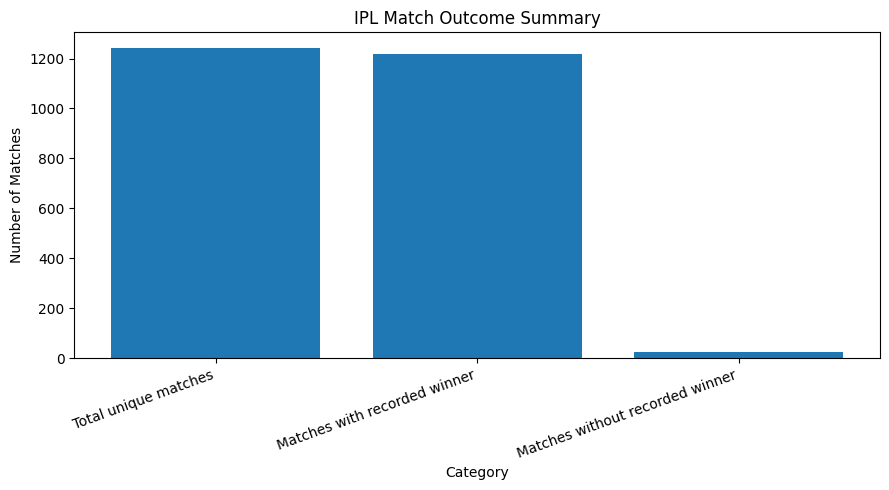

In [6]:
outcome_summary = pd.DataFrame({
    "category": [
        "Total unique matches",
        "Matches with recorded winner",
        "Matches without recorded winner"
    ],
    "count": [
        len(matches),
        int(matches["has_winner"].sum()),
        int((~matches["has_winner"]).sum())
    ]
})

display(outcome_summary)

plt.figure(figsize=(9, 5))
plt.bar(
    outcome_summary["category"],
    outcome_summary["count"]
)
plt.title("IPL Match Outcome Summary")
plt.xlabel("Category")
plt.ylabel("Number of Matches")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

,team,wins
0,Mumbai Indians,155
1,Chennai Super Kings,148
2,Kolkata Knight Riders,140
3,Rajasthan Royals,123
4,Royal Challengers Bangalore,114
5,Sunrisers Hyderabad,102
6,Kings XI Punjab,85
7,Delhi Daredevils,67
8,Delhi Capitals,58
9,Gujarat Titans,47


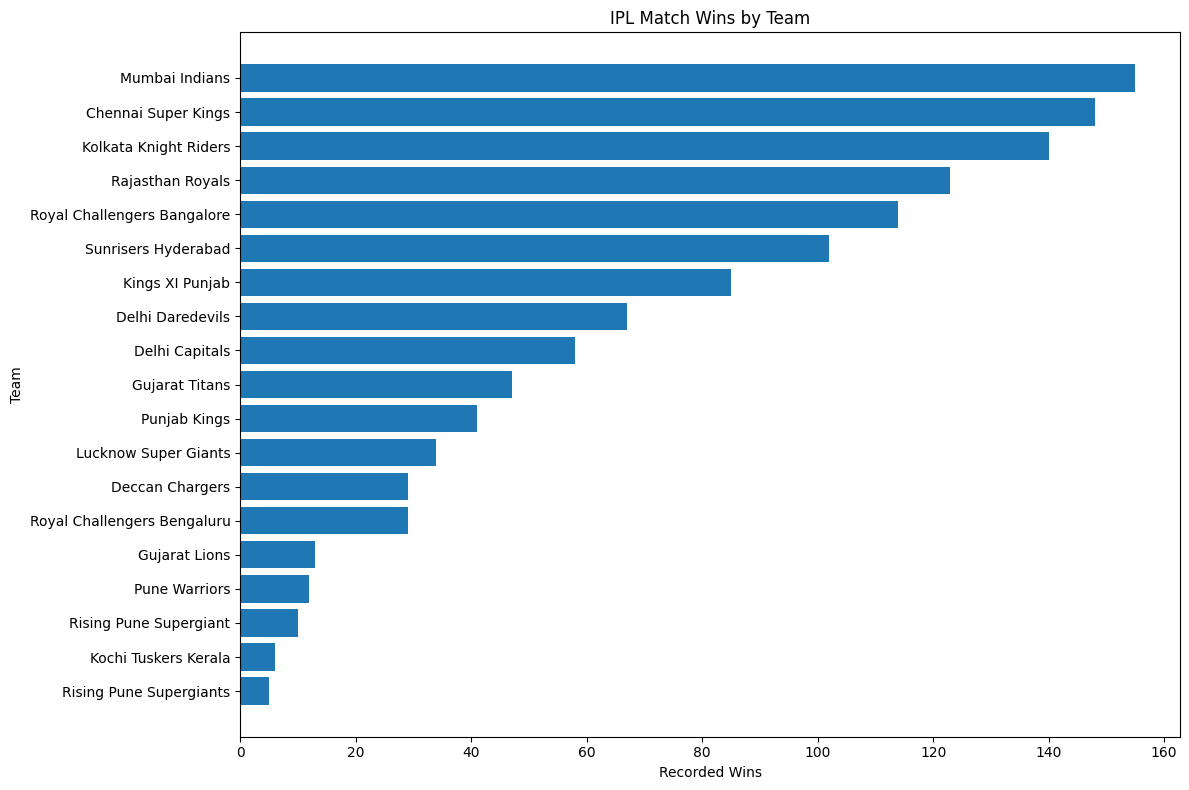

In [7]:
decided_matches = matches[matches["has_winner"]].copy()

team_wins = (
    decided_matches.groupby("winner")
    .size()
    .rename("wins")
    .reset_index()
    .rename(columns={"winner": "team"})
    .sort_values("wins", ascending=False)
    .reset_index(drop=True)
)

display(team_wins.head(20))

team_wins_plot = team_wins.sort_values("wins")

plt.figure(figsize=(12, 8))
plt.barh(team_wins_plot["team"], team_wins_plot["wins"])
plt.title("IPL Match Wins by Team")
plt.xlabel("Recorded Wins")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

,season,team,wins
2,2009.0,Delhi Daredevils,10
1,2009.0,Deccan Chargers,9
7,2009.0,Royal Challengers Bangalore,9
0,2009.0,Chennai Super Kings,8
3,2009.0,Kings XI Punjab,7
5,2009.0,Mumbai Indians,5
6,2009.0,Rajasthan Royals,5
4,2009.0,Kolkata Knight Riders,3
8,2011.0,Chennai Super Kings,11
14,2011.0,Mumbai Indians,10


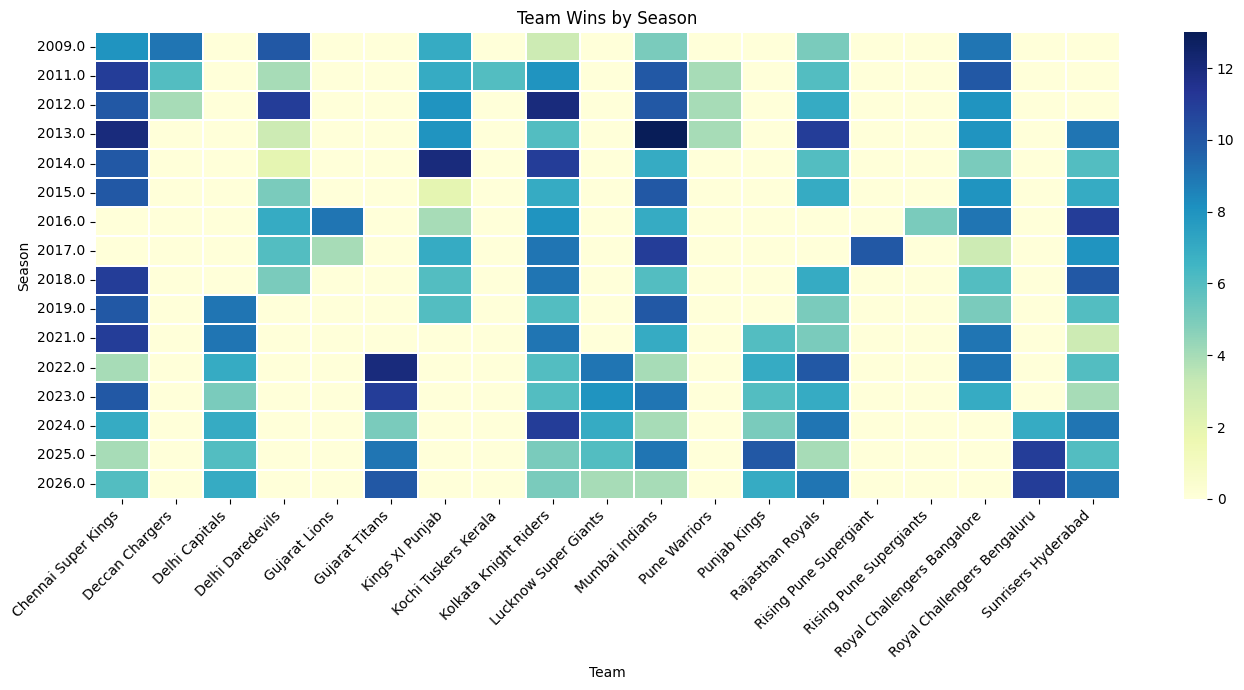

In [8]:
season_wins = (
    decided_matches.groupby(["season", "winner"])
    .size()
    .rename("wins")
    .reset_index()
    .rename(columns={"winner": "team"})
    .sort_values(["season", "wins"], ascending=[True, False])
)

display(season_wins.head(30))

season_pivot = season_wins.pivot(
    index="season",
    columns="team",
    values="wins"
).fillna(0)

plt.figure(figsize=(14, 7))
sns.heatmap(
    season_pivot,
    cmap="YlGnBu",
    linewidths=0.2
)
plt.title("Team Wins by Season")
plt.xlabel("Team")
plt.ylabel("Season")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

,toss_decision,matches
1,field,825
0,bat,418


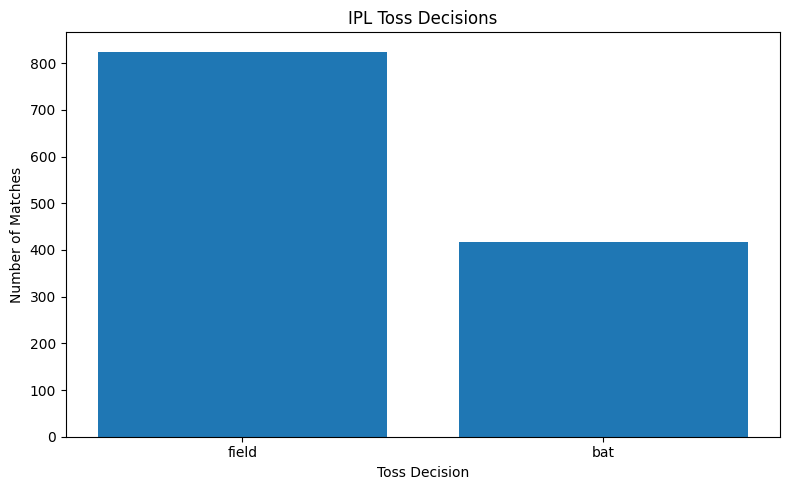

In [9]:
toss_decisions = (
    matches.dropna(subset=["toss_decision"])
    .groupby("toss_decision")
    .size()
    .rename("matches")
    .reset_index()
    .sort_values("matches", ascending=False)
)

display(toss_decisions)

plt.figure(figsize=(8, 5))
plt.bar(
    toss_decisions["toss_decision"],
    toss_decisions["matches"]
)
plt.title("IPL Toss Decisions")
plt.xlabel("Toss Decision")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

,outcome,matches,percentage
0,Toss winner lost match,590,48.440066
1,Toss winner also won match,628,51.559934


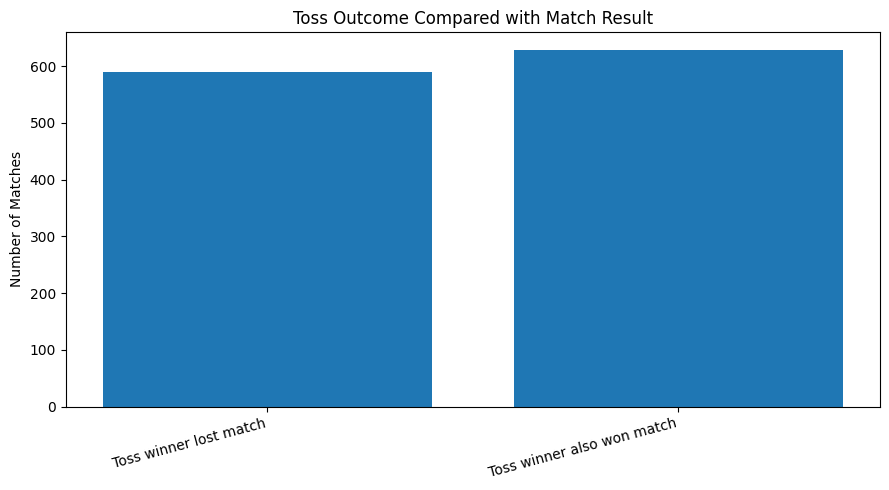

In [10]:
toss_decided = matches[
    matches["has_winner"]
    & matches["toss_winner"].notna()
].copy()

toss_decided["toss_won_match"] = (
    toss_decided["toss_winner"] == toss_decided["winner"]
)

toss_outcome_summary = (
    toss_decided.groupby("toss_won_match")
    .size()
    .rename("matches")
    .reset_index()
)

toss_outcome_summary["outcome"] = (
    toss_outcome_summary["toss_won_match"]
    .map({
        True: "Toss winner also won match",
        False: "Toss winner lost match"
    })
)

toss_outcome_summary["percentage"] = (
    toss_outcome_summary["matches"]
    / toss_outcome_summary["matches"].sum()
    * 100
)

display(toss_outcome_summary[["outcome", "matches", "percentage"]])

plt.figure(figsize=(9, 5))
plt.bar(
    toss_outcome_summary["outcome"],
    toss_outcome_summary["matches"]
)
plt.title("Toss Outcome Compared with Match Result")
plt.ylabel("Number of Matches")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

,toss_decision,toss_won_match,matches,result
0,bat,False,223,Toss winner lost match
1,bat,True,185,Toss winner won match
2,field,False,367,Toss winner lost match
3,field,True,443,Toss winner won match


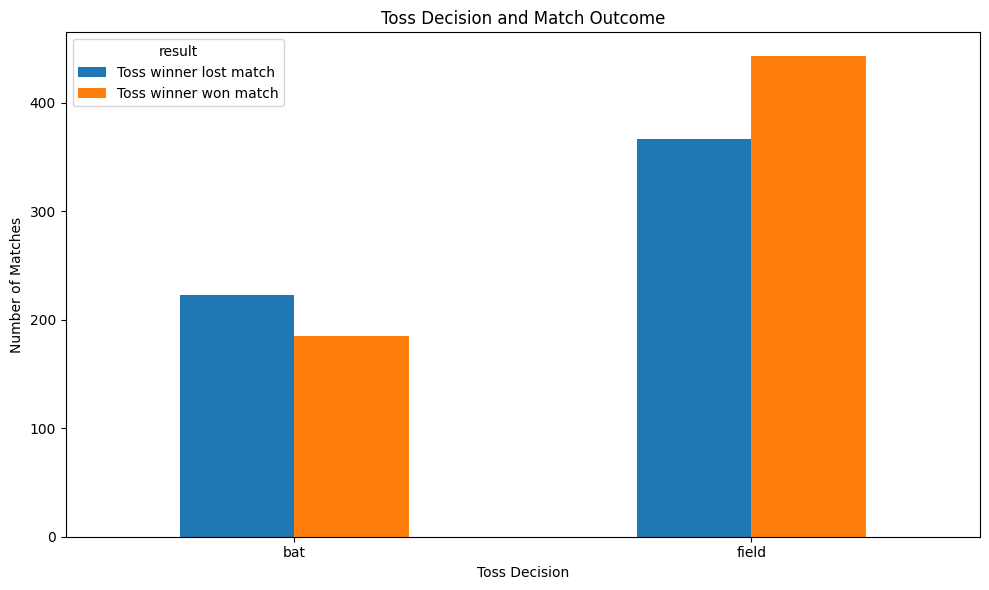

In [11]:
toss_decision_outcome = (
    toss_decided.groupby(
        ["toss_decision", "toss_won_match"]
    )
    .size()
    .rename("matches")
    .reset_index()
)

toss_decision_outcome["result"] = (
    toss_decision_outcome["toss_won_match"]
    .map({
        True: "Toss winner won match",
        False: "Toss winner lost match"
    })
)

display(toss_decision_outcome)

decision_pivot = toss_decision_outcome.pivot(
    index="toss_decision",
    columns="result",
    values="matches"
).fillna(0)

decision_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Toss Decision and Match Outcome")
plt.xlabel("Toss Decision")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
innings_scores = (
    deliveries_df.dropna(
        subset=["match_id", "innings", "batting_team"]
    )
    .groupby(
        ["match_id", "innings", "batting_team"],
        dropna=False
    )
    .agg(
        team_runs=("total_runs", "sum"),
        delivery_records=("total_runs", "size")
    )
    .reset_index()
)

display(
    innings_scores.sort_values(
        ["match_id", "innings"]
    ).head(20)
)

,match_id,innings,batting_team,team_runs,delivery_records
0,335982,1,Kolkata Knight Riders,222,124
1,335982,2,Royal Challengers Bangalore,82,101
2,335983,1,Chennai Super Kings,240,124
3,335983,2,Kings XI Punjab,207,124
4,335984,1,Rajasthan Royals,129,122
5,335984,2,Delhi Daredevils,132,97
6,335985,1,Mumbai Indians,165,123
7,335985,2,Royal Challengers Bangalore,166,123
8,335986,1,Deccan Chargers,110,118
9,335986,2,Kolkata Knight Riders,112,122


,match_id,first_batting_team,first_innings_runs,second_batting_team,second_innings_runs,winner,winner_runs,winner_wickets,result_type
0,335982,Kolkata Knight Riders,222,Royal Challengers Bangalore,82,Kolkata Knight Riders,140.0,NaN,Batting first won
1,335983,Chennai Super Kings,240,Kings XI Punjab,207,Chennai Super Kings,33.0,NaN,Batting first won
2,335984,Rajasthan Royals,129,Delhi Daredevils,132,Delhi Daredevils,NaN,9.0,Chasing team won
3,335985,Mumbai Indians,165,Royal Challengers Bangalore,166,Royal Challengers Bangalore,NaN,5.0,Chasing team won
4,335986,Deccan Chargers,110,Kolkata Knight Riders,112,Kolkata Knight Riders,NaN,5.0,Chasing team won
5,335987,Kings XI Punjab,166,Rajasthan Royals,168,Rajasthan Royals,NaN,6.0,Chasing team won
6,335988,Deccan Chargers,142,Delhi Daredevils,143,Delhi Daredevils,NaN,9.0,Chasing team won
7,335989,Chennai Super Kings,208,Mumbai Indians,202,Chennai Super Kings,6.0,NaN,Batting first won
8,335990,Deccan Chargers,214,Rajasthan Royals,217,Rajasthan Royals,NaN,3.0,Chasing team won
9,335991,Kings XI Punjab,182,Mumbai Indians,116,Kings XI Punjab,66.0,NaN,Batting first won


,result_type,matches
0,Batting first won,552
1,Chasing team won,666
2,No recorded winner / other result,19


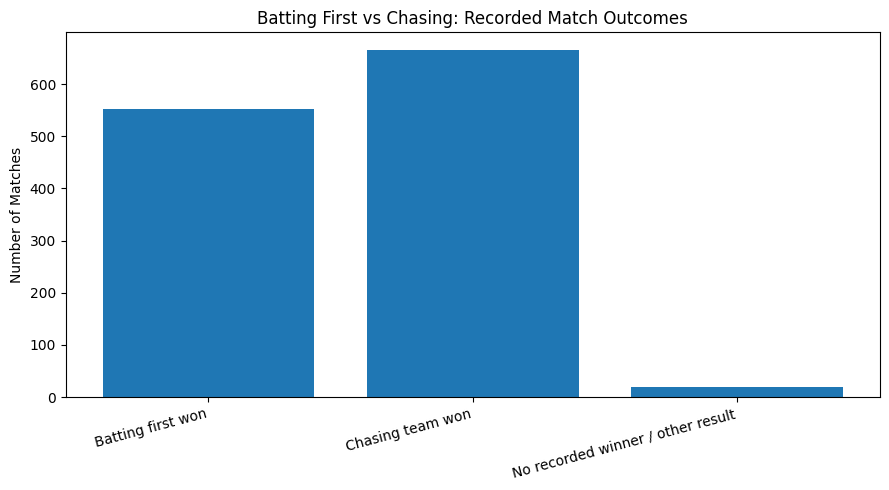

In [13]:
first_innings = (
    innings_scores[innings_scores["innings"] == 1]
    [["match_id", "batting_team", "team_runs"]]
    .rename(
        columns={
            "batting_team": "first_batting_team",
            "team_runs": "first_innings_runs"
        }
    )
)

second_innings = (
    innings_scores[innings_scores["innings"] == 2]
    [["match_id", "batting_team", "team_runs"]]
    .rename(
        columns={
            "batting_team": "second_batting_team",
            "team_runs": "second_innings_runs"
        }
    )
)

innings_comparison = first_innings.merge(
    second_innings,
    on="match_id",
    how="inner",
    validate="one_to_one"
).merge(
    matches[
        ["match_id", "winner", "winner_runs", "winner_wickets"]
    ],
    on="match_id",
    how="left",
    validate="one_to_one"
)

innings_comparison["result_type"] = np.select(
    [
        innings_comparison["winner"].eq(
            innings_comparison["first_batting_team"]
        ),
        innings_comparison["winner"].eq(
            innings_comparison["second_batting_team"]
        ),
    ],
    [
        "Batting first won",
        "Chasing team won"
    ],
    default="No recorded winner / other result"
)

display(innings_comparison.head(15))

result_counts = (
    innings_comparison.groupby("result_type")
    .size()
    .rename("matches")
    .reset_index()
)

display(result_counts)

plt.figure(figsize=(9, 5))
plt.bar(
    result_counts["result_type"],
    result_counts["matches"]
)
plt.title("Batting First vs Chasing: Recorded Match Outcomes")
plt.ylabel("Number of Matches")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

,innings,average_runs,median_runs,matches
0,First innings,168.57,168.0,1243
1,Second innings,155.13,157.0,1237


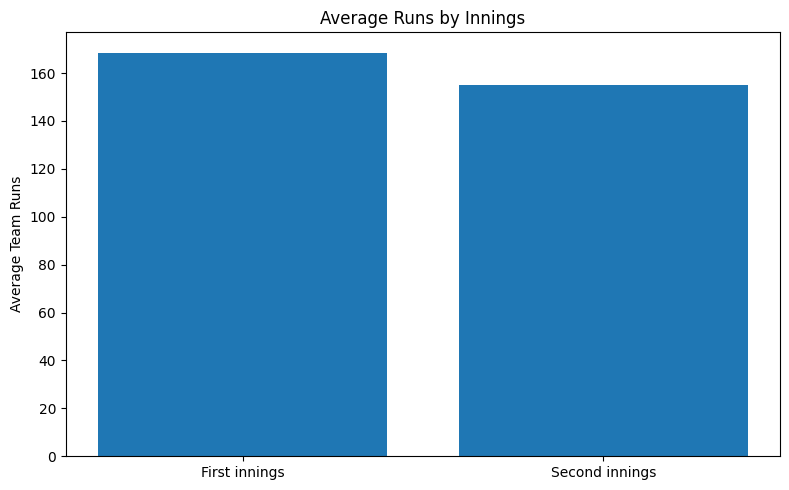

In [14]:
scoring_comparison = pd.DataFrame({
    "innings": ["First innings", "Second innings"],
    "average_runs": [
        first_innings["first_innings_runs"].mean(),
        second_innings["second_innings_runs"].mean()
    ],
    "median_runs": [
        first_innings["first_innings_runs"].median(),
        second_innings["second_innings_runs"].median()
    ],
    "matches": [
        first_innings["match_id"].nunique(),
        second_innings["match_id"].nunique()
    ]
})

display(scoring_comparison.round(2))

plt.figure(figsize=(8, 5))
plt.bar(
    scoring_comparison["innings"],
    scoring_comparison["average_runs"]
)
plt.title("Average Runs by Innings")
plt.ylabel("Average Team Runs")
plt.tight_layout()
plt.show()

In [15]:
margin_data = decided_matches.copy()

runs_margin = margin_data.dropna(subset=["winner_runs"])
wickets_margin = margin_data.dropna(subset=["winner_wickets"])

print("Matches with a recorded runs margin:", len(runs_margin))
print("Matches with a recorded wickets margin:", len(wickets_margin))

margin_summary = pd.DataFrame({
    "metric": [
        "Average win margin in runs",
        "Median win margin in runs",
        "Average win margin in wickets",
        "Median win margin in wickets"
    ],
    "value": [
        runs_margin["winner_runs"].mean(),
        runs_margin["winner_runs"].median(),
        wickets_margin["winner_wickets"].mean(),
        wickets_margin["winner_wickets"].median()
    ]
})

display(margin_summary.round(2))

Matches with a recorded runs margin: 558
Matches with a recorded wickets margin: 660


,metric,value
0,Average win margin in runs,31.04
1,Median win margin in runs,23.00
2,Average win margin in wickets,6.17
3,Median win margin in wickets,6.00


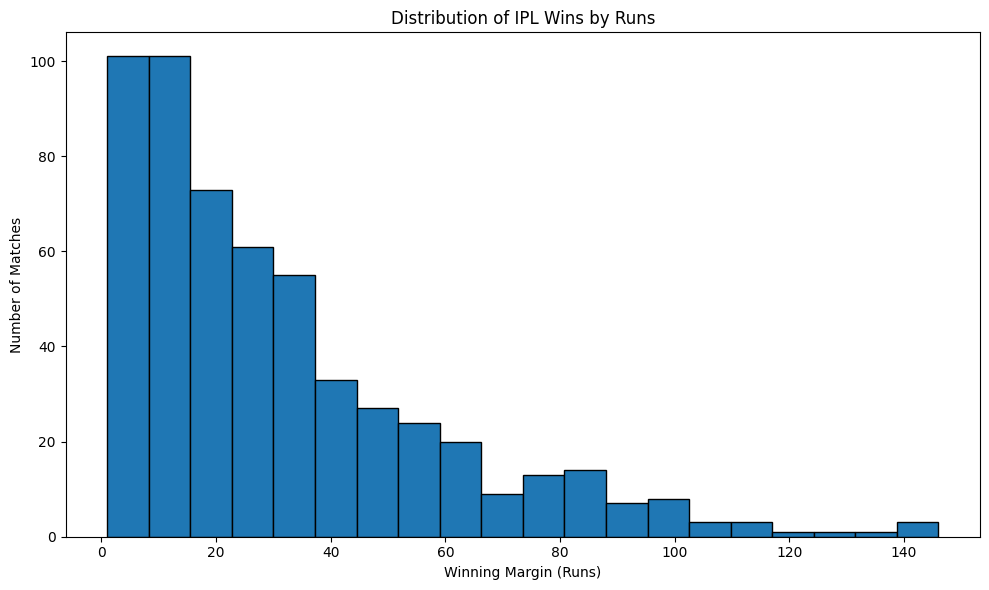

In [16]:
runs_margin = runs_margin[
    runs_margin["winner_runs"] > 0
].copy()

plt.figure(figsize=(10, 6))
plt.hist(
    runs_margin["winner_runs"],
    bins=20,
    edgecolor="black"
)
plt.title("Distribution of IPL Wins by Runs")
plt.xlabel("Winning Margin (Runs)")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

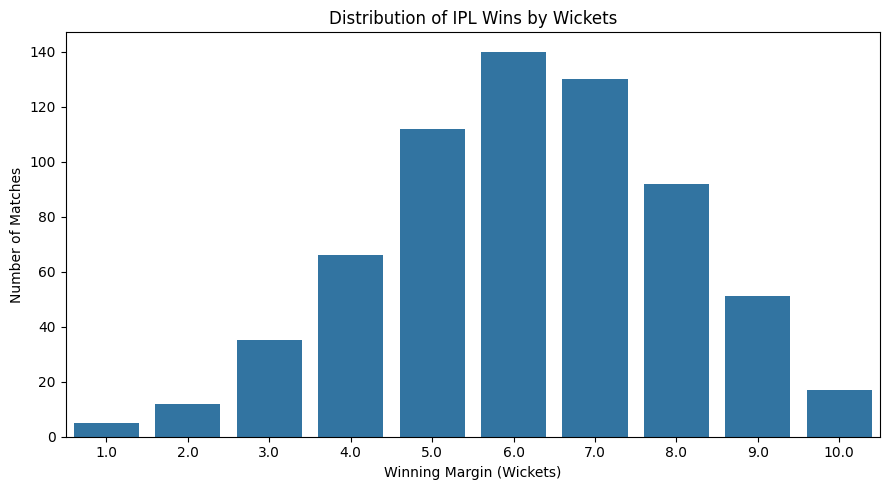

In [17]:
wickets_margin = wickets_margin[
    wickets_margin["winner_wickets"] > 0
].copy()

plt.figure(figsize=(9, 5))
sns.countplot(
    data=wickets_margin,
    x="winner_wickets",
    order=sorted(wickets_margin["winner_wickets"].dropna().unique())
)
plt.title("Distribution of IPL Wins by Wickets")
plt.xlabel("Winning Margin (Wickets)")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

,venue,matches,cities,recorded_winners
14,Eden Gardens,77,1,77
57,Wankhede Stadium,73,1,72
23,M Chinnaswamy Stadium,65,1,62
16,Feroz Shah Kotla,60,1,59
58,"Wankhede Stadium, Mumbai",59,1,59
43,"Rajiv Gandhi International Stadium, Uppal",49,1,48
27,"MA Chidambaram Stadium, Chepauk",48,1,47
47,Sawai Mansingh Stadium,47,1,47
13,Dubai International Cricket Stadium,46,1,43
33,"Narendra Modi Stadium, Ahmedabad",41,1,41


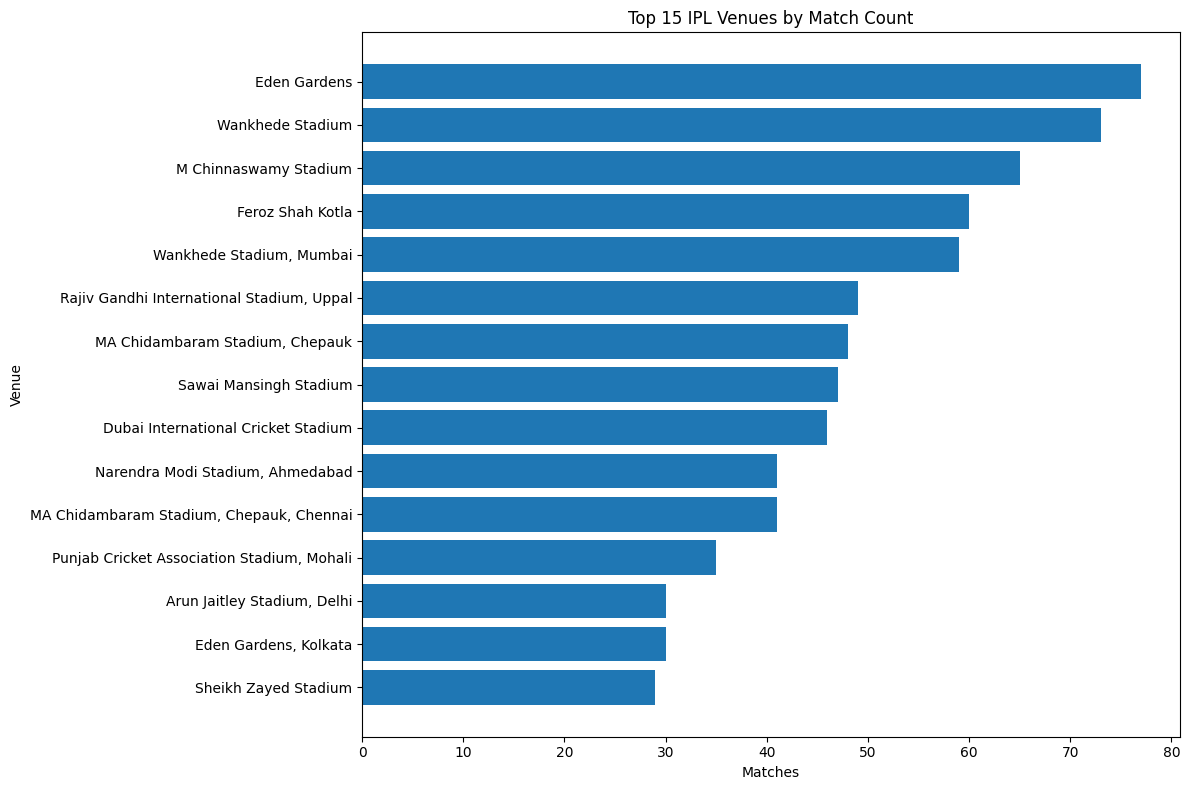

In [18]:
venue_matches = (
    matches.dropna(subset=["venue"])
    .groupby("venue")
    .agg(
        matches=("match_id", "nunique"),
        cities=("city", "nunique"),
        recorded_winners=("winner", "count")
    )
    .reset_index()
)

venue_matches = venue_matches.sort_values(
    "matches", ascending=False
)

display(venue_matches.head(20))

top_venues = (
    venue_matches.head(15)
    .sort_values("matches")
)

plt.figure(figsize=(12, 8))
plt.barh(top_venues["venue"], top_venues["matches"])
plt.title("Top 15 IPL Venues by Match Count")
plt.xlabel("Matches")
plt.ylabel("Venue")
plt.tight_layout()
plt.show()

,venue,innings_recorded,average_innings_runs,median_innings_runs,highest_innings_total,matches
14,Eden Gardens,154,153.623377,159.5,232,77
57,Wankhede Stadium,148,158.155405,165.0,235,73
23,M Chinnaswamy Stadium,131,154.679389,158.0,263,65
16,Feroz Shah Kotla,119,154.798319,161.0,231,60
58,"Wankhede Stadium, Mumbai",118,176.720339,180.5,249,59
43,"Rajiv Gandhi International Stadium, Uppal",100,148.880000,146.0,223,49
27,"MA Chidambaram Stadium, Chepauk",98,155.887755,152.5,246,48
47,Sawai Mansingh Stadium,94,151.744681,153.0,197,47
13,Dubai International Cricket Stadium,100,144.500000,156.5,219,46
33,"Narendra Modi Stadium, Ahmedabad",82,175.951220,171.5,243,41


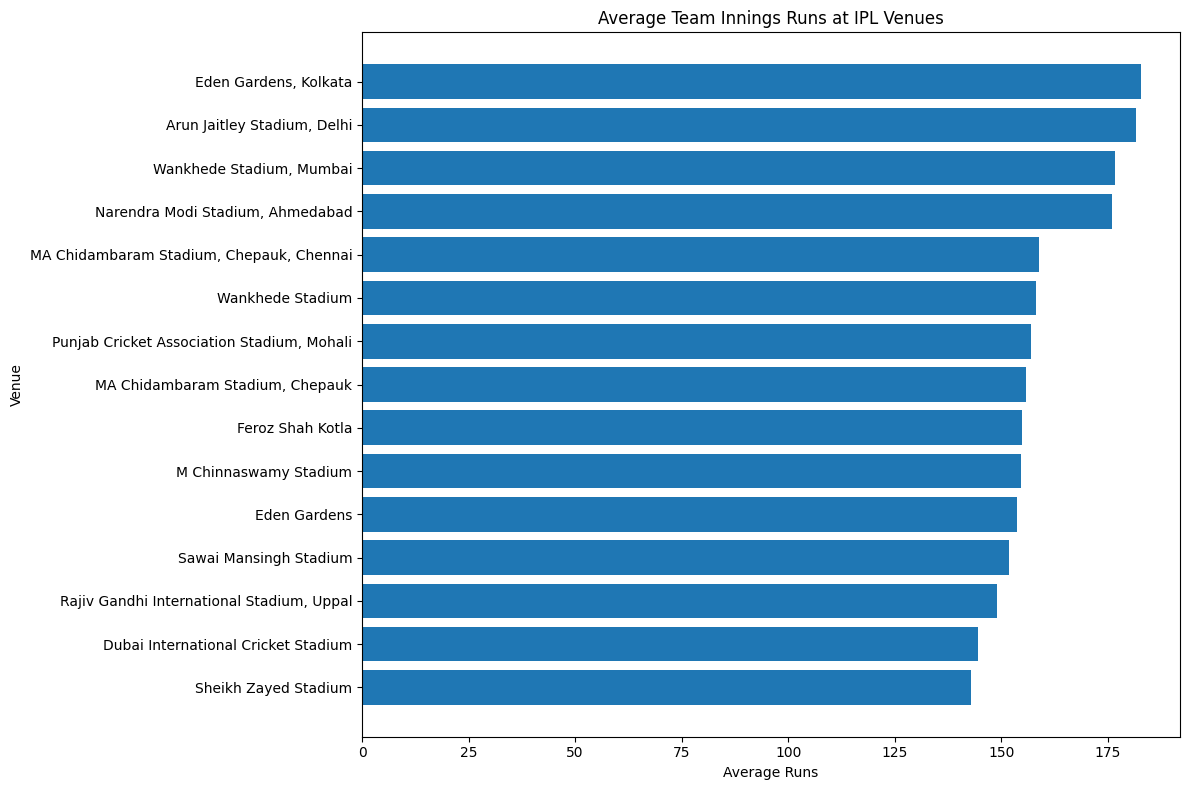

In [19]:
venue_scores = innings_scores.merge(
    matches[["match_id", "venue", "city", "season"]],
    on="match_id",
    how="left"
)

venue_scoring_summary = (
    venue_scores.dropna(subset=["venue"])
    .groupby("venue")
    .agg(
        innings_recorded=("team_runs", "size"),
        average_innings_runs=("team_runs", "mean"),
        median_innings_runs=("team_runs", "median"),
        highest_innings_total=("team_runs", "max"),
        matches=("match_id", "nunique")
    )
    .reset_index()
    .sort_values("matches", ascending=False)
)

display(venue_scoring_summary.head(20))

venue_scoring_plot = (
    venue_scoring_summary.nlargest(
        15, "matches"
    ).sort_values("average_innings_runs")
)

plt.figure(figsize=(12, 8))
plt.barh(
    venue_scoring_plot["venue"],
    venue_scoring_plot["average_innings_runs"]
)
plt.title("Average Team Innings Runs at IPL Venues")
plt.xlabel("Average Runs")
plt.ylabel("Venue")
plt.tight_layout()
plt.show()

,batting_team,total_runs,batter_runs,delivery_records,matches
10,Mumbai Indians,47641,45203,34990,291
8,Kolkata Knight Riders,43646,41248,32463,278
0,Chennai Super Kings,43600,41444,32101,265
13,Rajasthan Royals,40437,38532,29777,250
16,Royal Challengers Bangalore,37692,35810,28205,240
18,Sunrisers Hyderabad,34640,32920,25284,210
6,Kings XI Punjab,30064,28541,22646,190
3,Delhi Daredevils,24296,23022,18786,161
2,Delhi Capitals,19959,19051,14321,119
12,Punjab Kings,15509,14751,10454,87


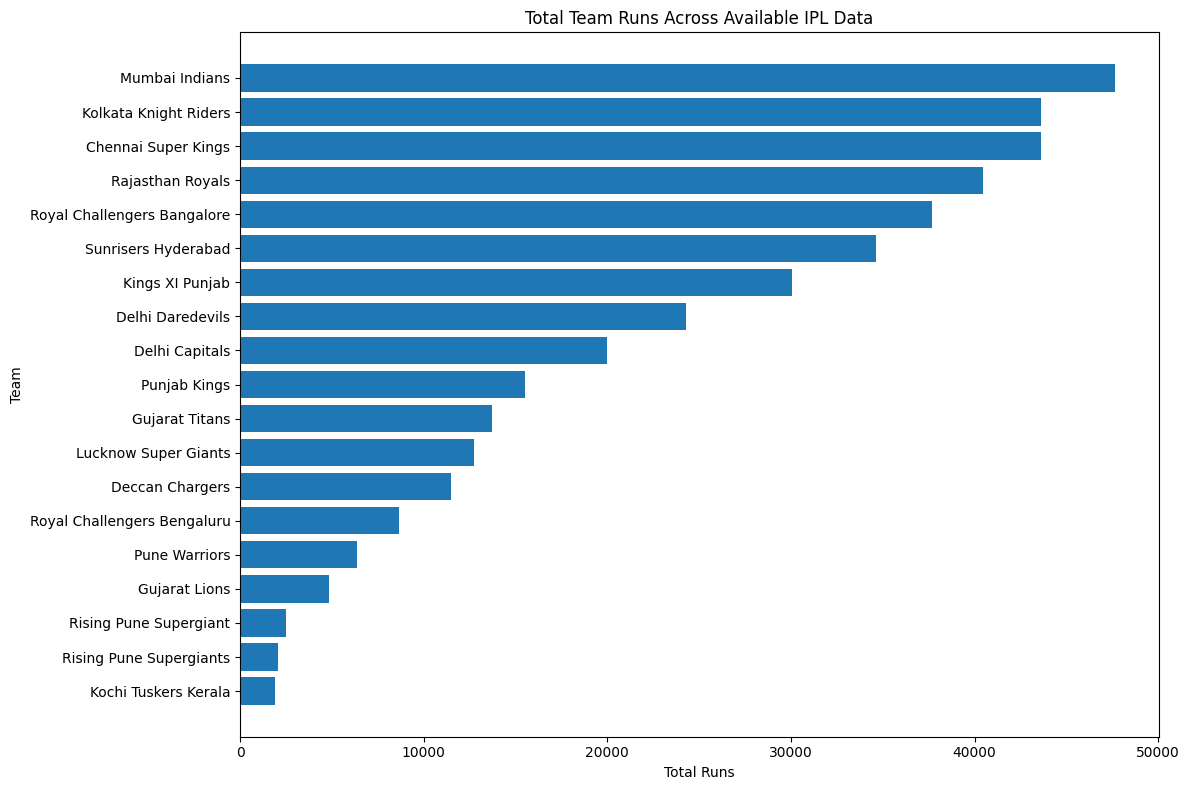

In [20]:
team_scoring = (
    deliveries_df.dropna(subset=["batting_team"])
    .groupby("batting_team")
    .agg(
        total_runs=("total_runs", "sum"),
        batter_runs=("runs_off_bat", "sum"),
        delivery_records=("total_runs", "size"),
        matches=("match_id", "nunique")
    )
    .reset_index()
    .sort_values("total_runs", ascending=False)
)

display(team_scoring)

team_scoring_plot = team_scoring.sort_values("total_runs")

plt.figure(figsize=(12, 8))
plt.barh(
    team_scoring_plot["batting_team"],
    team_scoring_plot["total_runs"]
)
plt.title("Total Team Runs Across Available IPL Data")
plt.xlabel("Total Runs")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

,venue,team,wins
94,Eden Gardens,Kolkata Knight Riders,45
384,Wankhede Stadium,Mumbai Indians,41
181,"MA Chidambaram Stadium, Chepauk",Chennai Super Kings,33
319,Sawai Mansingh Stadium,Rajasthan Royals,32
162,M Chinnaswamy Stadium,Royal Challengers Bangalore,28
112,Feroz Shah Kotla,Delhi Daredevils,23
292,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,19
229,"Narendra Modi Stadium, Ahmedabad",Gujarat Titans,18
269,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,18
396,"Wankhede Stadium, Mumbai",Mumbai Indians,17


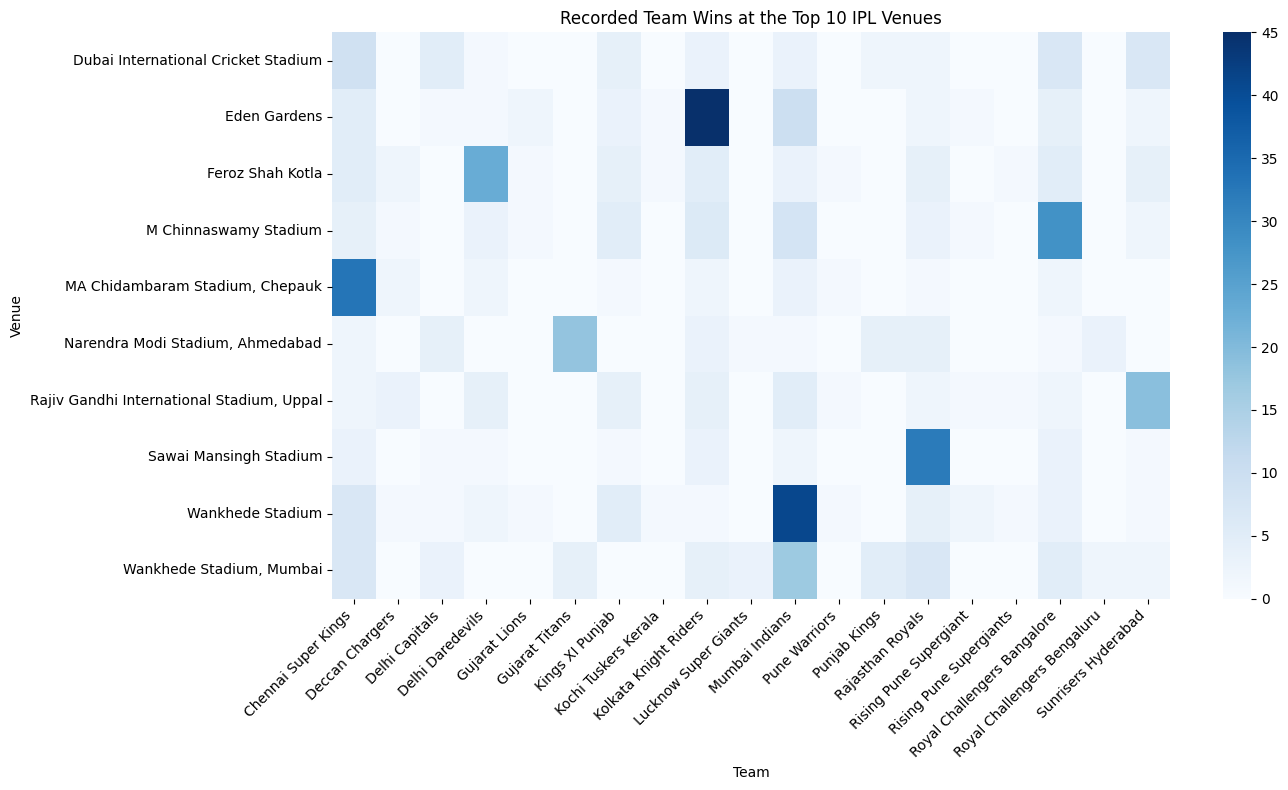

In [21]:
team_venue_wins = (
    decided_matches.dropna(subset=["venue"])
    .groupby(["venue", "winner"])
    .size()
    .rename("wins")
    .reset_index()
    .rename(columns={"winner": "team"})
    .sort_values("wins", ascending=False)
)

display(team_venue_wins.head(30))

top_venue_team_wins = team_venue_wins[
    team_venue_wins["venue"].isin(
        venue_matches.head(10)["venue"]
    )
]

venue_win_pivot = top_venue_team_wins.pivot(
    index="venue",
    columns="team",
    values="wins"
).fillna(0)

plt.figure(figsize=(14, 8))
sns.heatmap(venue_win_pivot, cmap="Blues")
plt.title("Recorded Team Wins at the Top 10 IPL Venues")
plt.xlabel("Team")
plt.ylabel("Venue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [22]:
print("TEAM & MATCH ANALYSIS VALIDATION")
print("-" * 45)

print("Unique matches:", matches["match_id"].nunique())
print("Matches with recorded winners:", int(matches["has_winner"].sum()))
print("Teams with recorded wins:", team_wins["team"].nunique())
print("Venue count:", venue_matches["venue"].nunique())
print("Innings records:", len(innings_scores))
print("Matches in batting-first/chasing comparison:", len(innings_comparison))

assert matches["match_id"].is_unique
assert (team_wins["wins"] >= 0).all()
assert (innings_scores["team_runs"] >= 0).all()
assert (venue_matches["matches"] >= 0).all()

print("\nBasic validation checks passed.")

TEAM & MATCH ANALYSIS VALIDATION
---------------------------------------------
Unique matches: 1243
Matches with recorded winners: 1218
Teams with recorded wins: 19
Venue count: 60
Innings records: 2514
Matches in batting-first/chasing comparison: 1237

Basic validation checks passed.


In [23]:
exports = {
    "match_outcome_summary.csv": outcome_summary,
    "team_wins.csv": team_wins,
    "season_wins.csv": season_wins,
    "toss_decision_summary.csv": toss_decisions,
    "toss_outcome_summary.csv": toss_outcome_summary,
    "toss_decision_outcome.csv": toss_decision_outcome,
    "innings_scores.csv": innings_scores,
    "innings_comparison.csv": innings_comparison,
    "innings_scoring_summary.csv": scoring_comparison,
    "win_margin_summary.csv": margin_summary,
    "venue_match_statistics.csv": venue_matches,
    "venue_scoring_statistics.csv": venue_scoring_summary,
    "team_scoring_statistics.csv": team_scoring,
    "team_venue_wins.csv": team_venue_wins,
}

for filename, dataframe in exports.items():
    dataframe.to_csv(OUTPUT_DIR / filename, index=False)

print("All team and match analysis files exported.")
print("Output directory:", OUTPUT_DIR)

for file_path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(file_path.name)

All team and match analysis files exported.
Output directory: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\TEAM_MATCH
innings_comparison.csv
innings_scores.csv
innings_scoring_summary.csv
match_outcome_summary.csv
season_wins.csv
team_scoring_statistics.csv
team_venue_wins.csv
team_wins.csv
toss_decision_outcome.csv
toss_decision_summary.csv
toss_outcome_summary.csv
venue_match_statistics.csv
venue_scoring_statistics.csv
win_margin_summary.csv


In [24]:
print("=" * 55)
print("IPL TEAM & MATCH ANALYSIS — SUMMARY")
print("=" * 55)

print("\nTop 10 teams by recorded wins:")
display(team_wins.head(10))

print("\nMost frequently used venues:")
display(venue_matches.head(10))

print("\nVenue scoring overview:")
display(
    venue_scoring_summary.sort_values(
        "average_innings_runs", ascending=False
    ).head(10).round(2)
)

print("\nToss outcome summary:")
display(
    toss_outcome_summary[
        ["outcome", "matches", "percentage"]
    ].round(2)
)

print("\nSeason-wise team wins:")
display(season_wins.head(20))

IPL TEAM & MATCH ANALYSIS — SUMMARY

Top 10 teams by recorded wins:


,team,wins
0,Mumbai Indians,155
1,Chennai Super Kings,148
2,Kolkata Knight Riders,140
3,Rajasthan Royals,123
4,Royal Challengers Bangalore,114
5,Sunrisers Hyderabad,102
6,Kings XI Punjab,85
7,Delhi Daredevils,67
8,Delhi Capitals,58
9,Gujarat Titans,47



Most frequently used venues:


,venue,matches,cities,recorded_winners
14,Eden Gardens,77,1,77
57,Wankhede Stadium,73,1,72
23,M Chinnaswamy Stadium,65,1,62
16,Feroz Shah Kotla,60,1,59
58,"Wankhede Stadium, Mumbai",59,1,59
43,"Rajiv Gandhi International Stadium, Uppal",49,1,48
27,"MA Chidambaram Stadium, Chepauk",48,1,47
47,Sawai Mansingh Stadium,47,1,47
13,Dubai International Cricket Stadium,46,1,43
33,"Narendra Modi Stadium, Ahmedabad",41,1,41



Venue scoring overview:


,venue,innings_recorded,average_innings_runs,median_innings_runs,highest_innings_total,matches
30,Maharaja Yadavindra Singh International Cricke...,14,212.93,219.0,254,7
19,"Himachal Pradesh Cricket Association Stadium, ...",19,196.84,199.0,254,10
12,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,8,193.62,181.0,272,4
44,"Rajiv Gandhi International Stadium, Uppal, Hyd...",51,188.33,185.0,286,26
48,"Sawai Mansingh Stadium, Jaipur",42,186.40,188.0,229,21
24,"M Chinnaswamy Stadium, Bengaluru",48,186.04,184.0,287,24
40,"Punjab Cricket Association IS Bindra Stadium, ...",10,185.60,182.5,257,5
15,"Eden Gardens, Kolkata",59,182.76,182.0,262,30
1,"Arun Jaitley Stadium, Delhi",62,181.52,188.0,278,30
50,Shaheed Veer Narayan Singh International Stadi...,4,179.75,179.5,194,2



Toss outcome summary:


,outcome,matches,percentage
0,Toss winner lost match,590,48.44
1,Toss winner also won match,628,51.56



Season-wise team wins:


,season,team,wins
2,2009.0,Delhi Daredevils,10
1,2009.0,Deccan Chargers,9
7,2009.0,Royal Challengers Bangalore,9
0,2009.0,Chennai Super Kings,8
3,2009.0,Kings XI Punjab,7
5,2009.0,Mumbai Indians,5
6,2009.0,Rajasthan Royals,5
4,2009.0,Kolkata Knight Riders,3
8,2011.0,Chennai Super Kings,11
14,2011.0,Mumbai Indians,10
